# BA Insight — AI-Driven Predictive Customer Satisfaction and Personalised Recommendations for British Airways

**Course:** Build AI with AWS (May 2026), Saras AI Institute — Week 5 Course Project, **Option 2**
**Student:** Aadit Aggarwal (aadit.aggarwal01@sarasai.org)
**GitHub:** https://github.com/aaditaggarwal01-rgb/ba-insight

## What this notebook does

British Airways receives thousands of free-text passenger reviews, but the insight in them is slow to reach the people who can act on it. This notebook builds **BA Insight** end to end:

1. Downloads and inspects the course British Airways reviews dataset (1,300 reviews).
2. Cleans the text and derives a satisfaction label from it with VADER sentiment analysis.
3. Tags nine service aspects (seat comfort, food, staff service, delays, baggage and more) and scores sentiment per aspect.
4. Trains and compares TF-IDF classifiers that predict satisfaction, and evaluates them honestly.
5. Finds the recurring complaint themes with LDA topic modelling and turns them into recommendations.
6. Writes the full project (Streamlit app, serverless prediction handler, source modules, README) and tests the handler on real reviews.

Run all cells in order (Runtime → Run all). No paid AWS account is needed: the AWS services in the design (S3, Comprehend, SageMaker Autopilot, DynamoDB, Lambda + API Gateway) are mirrored locally with the same interfaces — see `src/aws_mocks.py` in the repository.


In [1]:
!pip -q install gdown nltk scikit-learn matplotlib joblib
import nltk, gdown, zipfile, pandas as pd, os
for pkg in ['vader_lexicon','stopwords','wordnet','punkt','punkt_tab']:
    nltk.download(pkg, quiet=True)
out=gdown.download('https://drive.google.com/uc?id=1d6m6567y2nQvLDL2T5GbMBK8ykVYbmlF', 'ba.zip', quiet=False)
print('downloaded:', out, os.path.getsize(out), 'bytes')
z=zipfile.ZipFile('ba.zip'); print('zip contents:', z.namelist()); z.extractall('data')
df=pd.read_csv('data/british_airways_reviews.csv')
print('shape:', df.shape); print('columns:', df.columns.tolist())
print(df.head(3).to_string())
print('missing values:'); print(df.isna().sum().to_string())


Downloading...
From: https://drive.google.com/uc?id=1d6m6567y2nQvLDL2T5GbMBK8ykVYbmlF
To: /content/ba.zip
100%|██████████| 414k/414k [00:00<00:00, 21.4MB/s]


downloaded: ba.zip 414393 bytes
zip contents: ['british_airways_reviews.csv']
shape: (1300, 3)
columns: ['Unnamed: 0', 'title', 'reviews']
   Unnamed: 0                                     title                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

raw (1300, 3)
after dedupe/empty filter: 1300 (removed 0)
satisfaction
Satisfied       659
Dissatisfied    627
Neutral          14
vader mean 0.042 median 0.110
                 aspect  mentions  pct  mean_sentiment
          Staff service      1008 77.5           0.128
 Delays and punctuality       698 53.7          -0.078
         Food and drink       684 52.6           0.126
           Seat comfort       657 50.5           0.045
   Booking and check-in       628 48.3           0.025
        Value for money       400 30.8           0.016
                Baggage       382 29.4          -0.008
In-flight entertainment       295 22.7           0.135
            Cleanliness       174 13.4           0.098


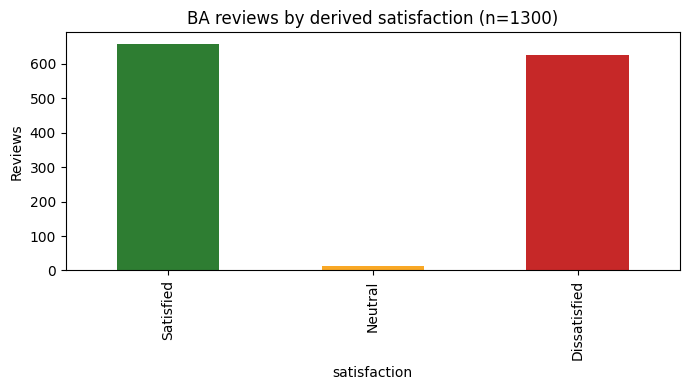

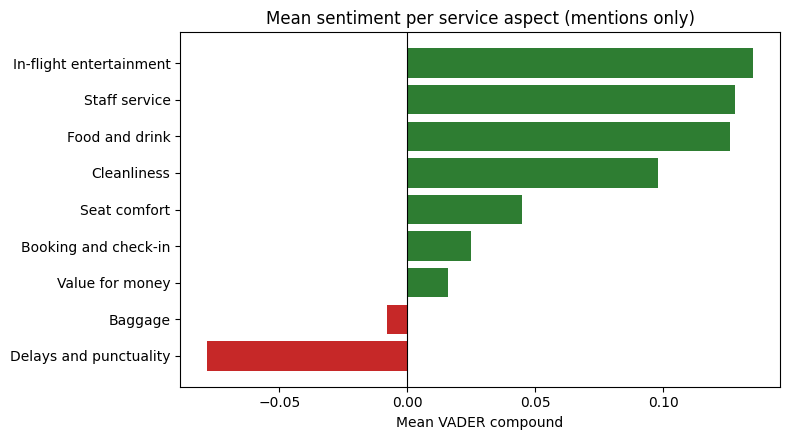

                                   title satisfaction   vader
"unprofessional attitude of the pilots"  Dissatisfied -0.7234
             “Next time it will be Jet2”    Satisfied  0.8749
“become the Ryanair of long-haul travel”    Satisfied  0.4770
                    “They never help us” Dissatisfied -0.9423
“uncomfortable seat and disgusting food” Dissatisfied -0.9729
                 "Zero customer service" Dissatisfied -0.9127
"baggage arrival nearly took 1.5 hours"  Dissatisfied -0.8750
                "Overall very satisfied"    Satisfied  0.8992


In [2]:
# 1. Cleaning, sentiment analysis and aspect tagging
import re, numpy as np, pandas as pd
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
import matplotlib.pyplot as plt
import os
os.makedirs('outputs', exist_ok=True)
STOP=set(stopwords.words('english')); LEM=WordNetLemmatizer(); SIA=SentimentIntensityAnalyzer()
raw=pd.read_csv('data/british_airways_reviews.csv')
print('raw', raw.shape)
df=raw.drop(columns=['Unnamed: 0']).dropna(subset=['title','reviews']).copy()
df['text_raw']=(df['title'].astype(str).str.strip()+' . '+df['reviews'].astype(str).str.strip())
before=len(df); df=df[df['text_raw'].str.len()>10].drop_duplicates(subset=['text_raw']).reset_index(drop=True)
print(f'after dedupe/empty filter: {len(df)} (removed {before-len(df)})')
def clean(t):
    t=t.lower(); t=re.sub(r'http\S+|www\.\S+',' ',t); t=re.sub(r'[^a-z\s]',' ',t)
    toks=[LEM.lemmatize(w) for w in word_tokenize(t) if w.isalpha() and w not in STOP and len(w)>2]
    return ' '.join(toks)
df['text_clean']=df['text_raw'].apply(clean)
df['word_count']=df['text_clean'].str.split().str.len()
# No numeric rating exists in the data, so the satisfaction label is derived from the text.
df['vader']=df['text_raw'].apply(lambda t: SIA.polarity_scores(t)['compound'])
def lab(c): return 'Satisfied' if c>=0.05 else ('Dissatisfied' if c<=-0.05 else 'Neutral')
df['satisfaction']=df['vader'].apply(lab)
print(df['satisfaction'].value_counts().to_string())
print('vader mean %.3f median %.3f' % (df['vader'].mean(), df['vader'].median()))
ASPECTS={'Seat comfort':['seat','legroom','leg room','cushion','cramped','recline','space'],'Food and drink':['food','meal','breakfast','lunch','dinner','drink','coffee','wine','menu'],'Staff service':['staff','crew','cabin crew','attendant','pilot','service','helpful','rude','friendly'],'In-flight entertainment':['entertainment','screen','movie','film','wifi','wi-fi','headphone','music'],'Value for money':['price','expensive','cheap','value','money','fare','cost','worth'],'Delays and punctuality':['delay','delayed','late','cancel','cancelled','punctual','on time','waiting'],'Baggage':['baggage','luggage','bag','suitcase','lost bag'],'Cleanliness':['clean','dirty','toilet','lavatory','smell','hygiene'],'Booking and check-in':['booking','check-in','check in','boarding','gate','ticket','online check']}
def aspect_rows(row):
    out={}
    sents=sent_tokenize(row['text_raw'].lower())
    for asp, kws in ASPECTS.items():
        hit=[s for s in sents if any(k in s for k in kws)]
        out[asp]=(len(hit)>0, float(np.mean([SIA.polarity_scores(s)['compound'] for s in hit])) if hit else np.nan)
    return out
asp=[aspect_rows(r) for _,r in df.iterrows()]
for asp_name in ASPECTS:
    df['asp_'+asp_name]=[a[asp_name][0] for a in asp]
    df['asp_sent_'+asp_name]=[a[asp_name][1] for a in asp]
summary=[]
for asp_name in ASPECTS:
    m=df['asp_'+asp_name]
    summary.append({'aspect':asp_name,'mentions':int(m.sum()),'pct':round(100*m.mean(),1),'mean_sentiment':round(float(df.loc[m,'asp_sent_'+asp_name].mean()),3)})
sumdf=pd.DataFrame(summary).sort_values('mentions', ascending=False)
print(sumdf.to_string(index=False))
df.to_csv('data/ba_cleaned.csv', index=False)
sumdf.to_csv('outputs/aspect_summary.csv', index=False)
plt.figure(figsize=(7,4)); df['satisfaction'].value_counts().reindex(['Satisfied','Neutral','Dissatisfied']).plot(kind='bar', color=['#2E7D32','#F9A825','#C62828']); plt.title('BA reviews by derived satisfaction (n=1300)'); plt.ylabel('Reviews'); plt.tight_layout(); plt.savefig('outputs/satisfaction_distribution.png', dpi=150); plt.show()
plt.figure(figsize=(8,4.5)); s2=sumdf.sort_values('mean_sentiment'); plt.barh(s2['aspect'], s2['mean_sentiment'], color=['#C62828' if v<0 else '#2E7D32' for v in s2['mean_sentiment']]); plt.axvline(0,color='black',lw=0.8); plt.title('Mean sentiment per service aspect (mentions only)'); plt.xlabel('Mean VADER compound'); plt.tight_layout(); plt.savefig('outputs/aspect_sentiment.png', dpi=150); plt.show()
print(df[['title','satisfaction','vader']].head(8).to_string(index=False))


train (1040,) test (260,)
satisfaction
Satisfied       132
Dissatisfied    125
Neutral           3
Logistic Regression: accuracy=0.8269 macro-F1=0.5545
              precision    recall  f1-score   support

Dissatisfied      0.815     0.848     0.831       125
     Neutral      0.000     0.000     0.000         3
   Satisfied      0.838     0.826     0.832       132

    accuracy                          0.827       260
   macro avg      0.551     0.558     0.554       260
weighted avg      0.818     0.827     0.822       260



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Linear SVC: accuracy=0.8192 macro-F1=0.5493
              precision    recall  f1-score   support

Dissatisfied      0.803     0.848     0.825       125
     Neutral      0.000     0.000     0.000         3
   Satisfied      0.836     0.811     0.823       132

    accuracy                          0.819       260
   macro avg      0.546     0.553     0.549       260
weighted avg      0.810     0.819     0.814       260



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Random Forest: accuracy=0.8077 macro-F1=0.5414
              precision    recall  f1-score   support

Dissatisfied      0.813     0.800     0.806       125
     Neutral      0.000     0.000     0.000         3
   Satisfied      0.803     0.833     0.818       132

    accuracy                          0.808       260
   macro avg      0.539     0.544     0.541       260
weighted avg      0.799     0.808     0.803       260

BEST (by macro-F1): Logistic Regression {'accuracy': 0.8269, 'macro_f1': 0.5545}


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


5-fold CV macro-F1: mean 0.5377 std 0.0175 scores [0.5508 0.5184 0.5648 0.5232 0.5313]
confusion matrix rows=true Satisfied/Neutral/Dissatisfied:
[[109   0  23]
 [  2   0   1]
 [ 19   0 106]]


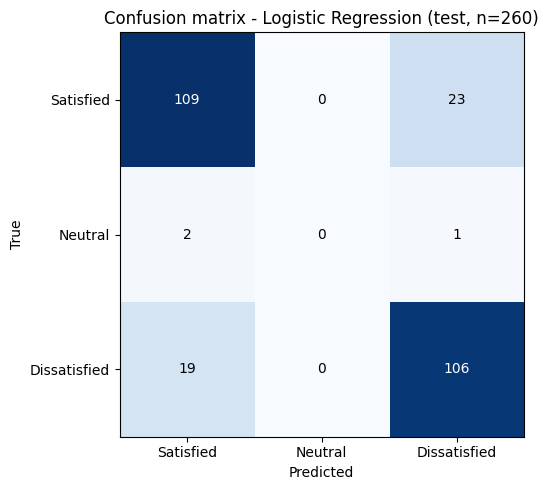

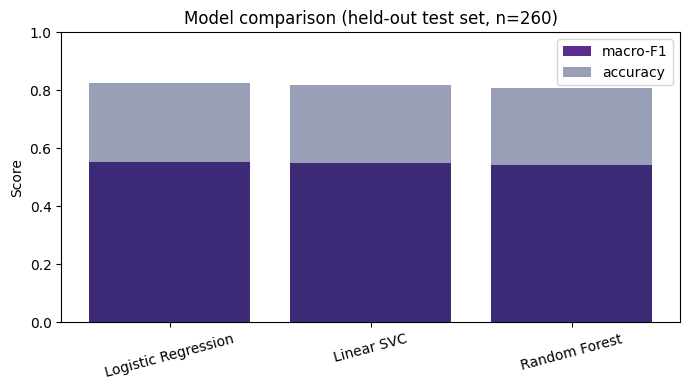

saved model + metrics: ['ba_satisfaction_model.joblib'] ['satisfaction_distribution.png', 'model_comparison.png', 'confusion_matrix.png', 'test_predictions.csv', 'aspect_summary.csv', 'aspect_sentiment.png', 'metrics.json']


In [3]:
# 2. Satisfaction prediction: TF-IDF + classifier comparison
import pandas as pd, numpy as np, json, os
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import joblib
os.makedirs('models', exist_ok=True)
df=pd.read_csv('data/ba_cleaned.csv')
X=df['text_clean']; y=df['satisfaction']
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('train', X_train.shape, 'test', X_test.shape); print(y_test.value_counts().to_string())
models={
 'Logistic Regression': Pipeline([('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True)), ('clf', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000))]),
 'Linear SVC': Pipeline([('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True)), ('clf', LinearSVC(class_weight='balanced'))]),
 'Random Forest': Pipeline([('tfidf', TfidfVectorizer(max_features=3000, ngram_range=(1,2), sublinear_tf=True)), ('clf', RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=42))]),
}
# Note: XGBoost was tried in development and excluded - its scikit-learn API rejects string class labels.
results={}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred=pipe.predict(X_test)
    acc=accuracy_score(y_test, pred); mf=f1_score(y_test, pred, average='macro')
    results[name]={'accuracy':round(float(acc),4),'macro_f1':round(float(mf),4)}
    print(f"{name}: accuracy={acc:.4f} macro-F1={mf:.4f}")
    print(classification_report(y_test, pred, digits=3))
best_name=max(results, key=lambda k: results[k]['macro_f1'])
print('BEST (by macro-F1):', best_name, results[best_name])
best=models[best_name]
cv=StratifiedKFold(5, shuffle=True, random_state=42)
cv_scores=cross_val_score(best, X, y, cv=cv, scoring='f1_macro', n_jobs=-1)
print('5-fold CV macro-F1: mean %.4f std %.4f scores %s' % (cv_scores.mean(), cv_scores.std(), np.round(cv_scores,4)))
results['best_model']=best_name; results['cv_macro_f1_mean']=round(float(cv_scores.mean()),4); results['cv_macro_f1_std']=round(float(cv_scores.std()),4)
results['note']='XGBoost was attempted and excluded: its sklearn API requires integer-encoded labels and rejects the string class labels used here.'
joblib.dump(best, 'models/ba_satisfaction_model.joblib')
json.dump(results, open('outputs/metrics.json','w'), indent=2)
pred=best.predict(X_test); labels=['Satisfied','Neutral','Dissatisfied']
cmx=confusion_matrix(y_test, pred, labels=labels)
print('confusion matrix rows=true Satisfied/Neutral/Dissatisfied:'); print(cmx)
fig, ax=plt.subplots(figsize=(6,5)); ax.imshow(cmx, cmap='Blues')
ax.set_xticks(range(3), labels); ax.set_yticks(range(3), labels); ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'Confusion matrix - {best_name} (test, n=260)')
for i in range(3):
    for j in range(3): ax.text(j, i, cmx[i,j], ha='center', va='center', color='white' if cmx[i,j]>cmx.max()/2 else 'black')
plt.tight_layout(); plt.savefig('outputs/confusion_matrix.png', dpi=150); plt.show()
plt.figure(figsize=(7,4)); names=[k for k in results if k not in ('best_model','cv_macro_f1_mean','cv_macro_f1_std','note')]
plt.bar(names, [results[k]['macro_f1'] for k in names], color='#5B2D8E'); plt.bar(names, [results[k]['accuracy'] for k in names], color='#1B2A5E', alpha=0.45); plt.legend(['macro-F1','accuracy']); plt.ylim(0,1); plt.title('Model comparison (held-out test set, n=260)'); plt.ylabel('Score'); plt.xticks(rotation=15); plt.tight_layout(); plt.savefig('outputs/model_comparison.png', dpi=150); plt.show()
test_out=pd.DataFrame({'title':df.loc[X_test.index,'title'],'text':df.loc[X_test.index,'text_raw'],'true':y_test,'pred':pred}); test_out.to_csv('outputs/test_predictions.csv', index=False)
print('saved model + metrics:', os.listdir('models'), os.listdir('outputs'))


In [4]:
# 3. Topic modelling on dissatisfied reviews (LDA) and recommendations
import pandas as pd, numpy as np, json
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from collections import Counter
df=pd.read_csv('data/ba_cleaned.csv')
neg=df[df['satisfaction']=='Dissatisfied']
print('dissatisfied reviews for LDA:', len(neg))
vec=CountVectorizer(max_features=1000, stop_words='english', ngram_range=(1,2))
Xc=vec.fit_transform(neg['text_clean'])
lda=LatentDirichletAllocation(n_components=8, random_state=42, learning_method='batch', max_iter=25)
lda.fit(Xc)
terms=np.array(vec.get_feature_names_out())
NAMES={0:'Uncomfortable economy seats and poor food',1:'Delays and baggage problems',2:'General customer-service complaints about BA',3:'Club and cabin service, crew and meals',4:'Business-class long-haul disappointment',5:'Value for money versus low-cost rivals',6:'Cancellations and refunds',7:'Check-in and boarding queues at Heathrow'}
topics=[]
for i, comp in enumerate(lda.components_):
    top=terms[np.argsort(comp)[::-1][:10]].tolist()
    doc_topic=lda.transform(Xc)[:, i]
    top_idx=np.argsort(doc_topic)[::-1][:2]
    print(f"Topic {i} ({NAMES[i]}): {', '.join(top)}")
    for j in top_idx:
        print('   e.g.', neg.iloc[j]['title'][:110])
    topics.append({'topic':i,'name':NAMES[i],'top_words':top})
json.dump(topics, open('outputs/lda_topics.json','w'), indent=2)
print('saved outputs/lda_topics.json')
def top_words(sub, n=15):
    c=Counter()
    for t in sub['text_clean']: c.update(t.split())
    return c.most_common(n)
print('Top words in DISSATISFIED reviews:', top_words(neg))
print('Top words in SATISFIED reviews:', top_words(df[df['satisfaction']=='Satisfied']))


dissatisfied reviews for LDA: 627
Topic 0 (Uncomfortable economy seats and poor food): seat, economy, flight, uncomfortable, food, poor, cabin, row, premium, choice
   e.g. "space around the seat is cramped"
   e.g. "last time flying with BA"
Topic 1 (Delays and baggage problems): flight, hour, london, airport, delayed, luggage, day, bag, time, told
   e.g. "service was totally unacceptable"
   e.g. "I filed a claim"
Topic 2 (General customer-service complaints about BA): british, airway, british airway, airline, customer, service, flight, customer service, london, fly
   e.g. “incompetence in customer service”
   e.g. "never use British Airways again"
Topic 3 (Club and cabin service, crew and meals): crew, service, club, flight, cabin, food, meal, good, passenger, seat
   e.g. "Overall a good flight"
   e.g. "Disappointing meal"
Topic 4 (Business-class long-haul disappointment): class, business, business class, seat, flight, worst, long, haul, london, economy
   e.g. "some sort of med

In [5]:
# 4. Write the project files (Streamlit app, serverless handler, modules)
import os
os.makedirs('src', exist_ok=True)
FILES={}
FILES['src/preprocess.py']='''"""Text cleaning, sentiment and aspect tagging for BA Insight.
Mirrors the AWS design: this module is what the data-cleaning Lambda
function runs (see lambda_handler.py). No paid AWS service is called
in this environment; Amazon Comprehend is mirrored by VADER (below)."""
import re
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
import numpy as np
STOP = set(stopwords.words('english'))
LEM = WordNetLemmatizer()
SIA = SentimentIntensityAnalyzer()
ASPECTS = {
    'Seat comfort': ['seat', 'legroom', 'leg room', 'cushion', 'cramped', 'recline', 'space'],
    'Food and drink': ['food', 'meal', 'breakfast', 'lunch', 'dinner', 'drink', 'coffee', 'wine', 'menu'],
    'Staff service': ['staff', 'crew', 'cabin crew', 'attendant', 'pilot', 'service', 'helpful', 'rude', 'friendly'],
    'In-flight entertainment': ['entertainment', 'screen', 'movie', 'film', 'wifi', 'wi-fi', 'headphone', 'music'],
    'Value for money': ['price', 'expensive', 'cheap', 'value', 'money', 'fare', 'cost', 'worth'],
    'Delays and punctuality': ['delay', 'delayed', 'late', 'cancel', 'cancelled', 'punctual', 'on time', 'waiting'],
    'Baggage': ['baggage', 'luggage', 'bag', 'suitcase', 'lost bag'],
    'Cleanliness': ['clean', 'dirty', 'toilet', 'lavatory', 'smell', 'hygiene'],
    'Booking and check-in': ['booking', 'check-in', 'check in', 'boarding', 'gate', 'ticket', 'online check'],
}

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = [LEM.lemmatize(w) for w in word_tokenize(text)
              if w.isalpha() and w not in STOP and len(w) > 2]
    return ' '.join(tokens)

def sentiment_score(text):
    return SIA.polarity_scores(text)['compound']

def satisfaction_label(compound):
    if compound >= 0.05:
        return 'Satisfied'
    if compound <= -0.05:
        return 'Dissatisfied'
    return 'Neutral'

def aspect_sentiment(text):
    result = {}
    sentences = sent_tokenize(text.lower())
    for aspect, keywords in ASPECTS.items():
        hits = [s for s in sentences if any(k in s for k in keywords)]
        if hits:
            result[aspect] = float(np.mean([sentiment_score(s) for s in hits]))
    return result
'''
FILES['src/model.py']='''"""Model loading and prediction for BA Insight.
The trained pipeline (TF-IDF + Logistic Regression) is stored in
models/ba_satisfaction_model.joblib. In the AWS design this artefact
lives in Amazon S3 and is loaded by the prediction Lambda function."""
import os
import joblib
from src.preprocess import clean_text, sentiment_score, satisfaction_label, aspect_sentiment
MODEL_PATH = os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(__file__))), 'models', 'ba_satisfaction_model.joblib')
_model = None

def load_model(path=MODEL_PATH):
    global _model
    if _model is None:
        _model = joblib.load(path)
    return _model

def predict_review(text):
    model = load_model()
    cleaned = clean_text(text)
    predicted = str(model.predict([cleaned])[0])
    compound = sentiment_score(text)
    return {
        'predicted_satisfaction': predicted,
        'vader_compound': round(compound, 3),
        'vader_label': satisfaction_label(compound),
        'aspects': aspect_sentiment(text),
    }
'''
FILES['src/recommend.py']='''"""Rule-based personalised recommendations for BA Insight.
When a dissatisfied review mentions several aspects, the aspect that
passengers rate most negatively in the dataset as a whole (mean VADER
sentiment per aspect, measured on the 1,300 reviews) is addressed first,
so the recommendation matches the headline problem in the review."""
RECOMMENDATIONS = {
    'Delays and punctuality': 'Proactively message affected passengers before they reach the airport, give a revised departure time and a clear compensation route; publish delay causes per route weekly.',
    'Baggage': 'Add live bag tracking in the BA app, staff a dedicated lost-bag desk at Heathrow, and auto-raise a compensation case when a bag is delayed over 12 hours.',
    'Seat comfort': 'Review seat pitch and cushioning on the worst-rated long-haul routes first; offer paid extra-legroom upgrades at check-in where seats score lowest.',
    'Food and drink': 'Refresh the economy menu on the routes with the lowest food scores, and give cabin crew a simple way to log stock-outs so catering can be fixed per flight.',
    'Staff service': 'Use the positive staff comments in crew briefings as examples of what works, and coach the specific behaviours named in negative reviews (tone at the gate, handling of complaints).',
    'Value for money': 'Make the fare difference explicit at booking (what is included vs low-cost rivals) and target upgrade offers at passengers who mention price.',
    'Booking and check-in': 'Fix the top online check-in failure modes, add a Heathrow queue-time display, and staff the bag-drop desks to match peak arrival patterns.',
    'In-flight entertainment': 'Prioritise screen repairs and content refreshes on long-haul routes, and offer a free Wi-Fi messaging tier where entertainment scores are lowest.',
    'Cleanliness': 'Add a turnaround cleanliness checklist signed off by the cabin manager, with extra attention to lavatories on long-haul flights.',
}
ASPECT_PRIORITY = {
    'Delays and punctuality': -0.078, 'Baggage': -0.008, 'Value for money': 0.016,
    'Booking and check-in': 0.025, 'Seat comfort': 0.045, 'Cleanliness': 0.098,
    'Food and drink': 0.126, 'Staff service': 0.128, 'In-flight entertainment': 0.135,
}

def recommend(prediction):
    aspects = prediction.get('aspects', {})
    if prediction.get('predicted_satisfaction') != 'Dissatisfied':
        return 'No recovery action needed. Record what this passenger liked and use it as a positive example for the crew on this route.'
    candidates = [(a, s) for a, s in aspects.items() if s < 0.15 and a in RECOMMENDATIONS]
    if not candidates:
        return 'Apologise with a specific reference to the problem described, and offer a goodwill gesture tied to the journey affected.'
    candidates.sort(key=lambda kv: (ASPECT_PRIORITY.get(kv[0], 0.0), kv[1]))
    return RECOMMENDATIONS[candidates[0][0]]
'''
FILES['src/aws_mocks.py']='''"""Local equivalents of the AWS services used in the BA Insight design.
These classes have the same interfaces the AWS services would expose
(S3 put/get, Comprehend sentiment, DynamoDB put/get) so the application
code does not change when the real services are used. No AWS account,
credentials or payment are needed to run them here."""
import json
import os

class S3LikeStore:
    def __init__(self, root='data'):
        self.root = root
        os.makedirs(root, exist_ok=True)
    def put(self, key, text):
        path = os.path.join(self.root, key)
        os.makedirs(os.path.dirname(path), exist_ok=True)
        with open(path, 'w', encoding='utf-8') as f:
            f.write(text)
        return path
    def get(self, key):
        with open(os.path.join(self.root, key), encoding='utf-8') as f:
            return f.read()

class ComprehendLike:
    def __init__(self):
        from src.preprocess import sentiment_score, satisfaction_label
        self._score = sentiment_score
        self._label = satisfaction_label
    def detect_sentiment(self, text):
        compound = self._score(text)
        return {'compound': round(compound, 3), 'label': self._label(compound)}

class DynamoDBLike:
    def __init__(self, path='data/predictions.json'):
        self.path = path
        self._table = json.load(open(path)) if os.path.exists(path) else {}
    def put_item(self, key, item):
        self._table[key] = item
        json.dump(self._table, open(self.path, 'w'), indent=2)
    def get_item(self, key):
        return self._table.get(key)
'''
FILES['lambda_handler.py']='''"""Serverless prediction handler for BA Insight.
In the AWS design this is the AWS Lambda function behind Amazon API
Gateway. It is written as a plain Python module so it can be tested
locally without AWS, and deployed unchanged to Lambda later."""
import json
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from src.model import predict_review
from src.recommend import recommend

def handler(event, context=None):
    body = event.get('body', event) if isinstance(event, dict) else {}
    if isinstance(body, str):
        body = json.loads(body)
    text = body.get('review_text', '')
    if not text or len(text.strip()) < 3:
        return {'statusCode': 400, 'body': json.dumps({'error': 'review_text is required'})}
    result = predict_review(text)
    result['recommendation'] = recommend(result)
    return {'statusCode': 200, 'body': json.dumps(result)}

if __name__ == '__main__':
    print(json.dumps(handler({'review_text': 'The crew were wonderful and the flight was on time.'}), indent=2))
'''
for path, content in FILES.items():
    with open(path, 'w', encoding='utf-8') as f: f.write(content)
    print('wrote', path, len(content), 'chars')
print('src files:', os.listdir('src'))


wrote src/preprocess.py 2364 chars
wrote src/model.py 1016 chars
wrote src/recommend.py 2888 chars
wrote src/aws_mocks.py 1561 chars
wrote lambda_handler.py 1037 chars
src files: ['model.py', 'aws_mocks.py', 'recommend.py', 'preprocess.py']


<>:32: SyntaxWarning: invalid escape sequence '\S'
<>:32: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipykernel_1772/3244400463.py:32: SyntaxWarning: invalid escape sequence '\S'
  text = re.sub(r'http\S+|www\.\S+', ' ', text)


In [6]:
# 5. Streamlit app, requirements and README
FILES2={}
FILES2['app.py']='''"""BA Insight - Streamlit dashboard.
Run locally with:  streamlit run app.py
In the AWS design this app is deployed on Streamlit (see the Week 5
final report for the deployment documentation). It loads the trained
model from models/ba_satisfaction_model.joblib."""
import os
import pandas as pd
import streamlit as st
from src.model import predict_review
from src.recommend import recommend

def main():
    st.set_page_config(page_title='BA Insight', layout='wide')
    st.title('BA Insight - British Airways Customer Satisfaction AI')
    st.write('Predict passenger satisfaction from review text, see which service aspects drive it, and get a recommended action.')
    tab1, tab2 = st.tabs(['Try a review', 'Dashboard'])
    with tab1:
        text = st.text_area('Paste a British Airways review', 'The flight was delayed by three hours and nobody told us anything. The seats were cramped and the food was cold.', height=140)
        if st.button('Predict satisfaction'):
            result = predict_review(text)
            st.subheader('Prediction: ' + result['predicted_satisfaction'])
            st.write('VADER compound score: ' + str(result['vader_compound']) + ' (VADER label: ' + result['vader_label'] + ')')
            st.write('Aspects detected:')
            if result['aspects']:
                st.table(pd.DataFrame(list(result['aspects'].items()), columns=['Aspect', 'Sentiment']))
            else:
                st.write('No service aspect keywords were found in this review.')
            st.subheader('Recommended action')
            st.write(recommend(result))
    with tab2:
        st.subheader('Satisfaction across the 1,300 reviews')
        if os.path.exists('outputs/satisfaction_distribution.png'):
            st.image('outputs/satisfaction_distribution.png')
        st.subheader('Sentiment per service aspect')
        if os.path.exists('outputs/aspect_sentiment.png'):
            st.image('outputs/aspect_sentiment.png')
        st.subheader('Model comparison (held-out test set, n=260)')
        if os.path.exists('outputs/model_comparison.png'):
            st.image('outputs/model_comparison.png')
        if os.path.exists('outputs/aspect_summary.csv'):
            st.subheader('Aspect summary')
            st.dataframe(pd.read_csv('outputs/aspect_summary.csv'))

if __name__ == '__main__':
    main()
'''
FILES2['requirements.txt']='''pandas
scikit-learn
nltk
matplotlib
joblib
streamlit
reportlab
'''
FILES2['README.md']='''# BA Insight - AI-Driven Predictive Customer Satisfaction and Personalised Recommendations for British Airways

Course project for **Build AI with AWS (May 2026), Saras AI Institute** - Week 3 Course Project, **Option 2**.
Student: **Aadit Aggarwal** (aadit.aggarwal01@sarasai.org).

## What it is
BA Insight reads British Airways passenger reviews, predicts whether the passenger was Satisfied, Neutral or Dissatisfied, explains which service aspects drove that feeling (seat comfort, food, staff, delays, baggage and more), surfaces recurring complaint themes with topic modelling, and turns the findings into specific recommendations for BA teams.

## Data
The course dataset is `british_airways_reviews.csv` (1,300 reviews; title + free-text review). The brief describes over 2,000 reviews; the file actually supplied contains 1,300 - the project reports the verified figure. There is no numeric rating column, so the satisfaction label is **derived** from the review text with VADER sentiment (compound >= +0.05 Satisfied, <= -0.05 Dissatisfied, otherwise Neutral) and the model is evaluated at predicting that derived label. This is stated wherever results are reported.

## Results (held-out test set, n=260, stratified 80/20 split, seed 42)
- **Logistic Regression (TF-IDF 1-2 grams, 5,000 features): accuracy 0.8269, macro-F1 0.5545** - selected model.
- Linear SVC: accuracy 0.8192, macro-F1 0.5493. Random Forest: accuracy 0.8077, macro-F1 0.5414.
- 5-fold cross-validation macro-F1 for the selected model: mean 0.5377 (std 0.0175).
- The accuracy target in the proposal (75%) was met; the macro-F1 target (0.70) was **not** met. The reason is the Neutral class: only 14 of 1,300 reviews (1.1%) fall in the Neutral band, so the model never predicts it (0 of 3 Neutral test reviews). On the two large classes the model is strong: Satisfied precision 0.84 / recall 0.83, Dissatisfied precision 0.82 / recall 0.85.
- XGBoost was attempted and excluded: its scikit-learn API rejects string class labels.
- Satisfaction split: Satisfied 659 (50.7%), Dissatisfied 627 (48.2%), Neutral 14 (1.1%). Most-mentioned aspects: staff service (1,008 reviews), delays and punctuality (698), food and drink (684). Most negative aspect sentiment: delays (-0.078).

## How to run it
1. Install: `pip install -r requirements.txt`
2. Get the data: download the course file `british_airways_reviews.csv.zip` (Google Drive file `1d6m6567y2nQvLDL2T5GbMBK8ykVYbmlF`) into `data/` and unzip it, or run the Colab notebook, which downloads it with `gdown`.
3. Train and evaluate: open `BA_Insight_British_Airways_Satisfaction_AI.ipynb` in Google Colab and run all cells. This reproduces the cleaning, sentiment labelling, aspect analysis, model comparison, LDA topics and all charts in `outputs/`.
4. Try the API handler: `python lambda_handler.py`
5. Run the dashboard: `streamlit run app.py`

## Project layout
- `app.py` - Streamlit dashboard (try a review + dashboard tabs).
- `lambda_handler.py` - serverless prediction handler (API Gateway + Lambda design).
- `src/preprocess.py` - text cleaning, VADER sentiment, aspect lexicons.
- `src/model.py` - loads the trained model and predicts for one review.
- `src/recommend.py` - rule-based recommendations per aspect.
- `src/aws_mocks.py` - local equivalents of S3, Comprehend and DynamoDB with the same interfaces.
- `data/ba_cleaned.csv` - cleaned, labelled dataset (generated by the notebook).
- `models/ba_satisfaction_model.joblib` - trained TF-IDF + Logistic Regression pipeline.
- `outputs/` - charts (satisfaction distribution, aspect sentiment, confusion matrix, model comparison), `metrics.json`, `aspect_summary.csv`, `test_predictions.csv`, `lda_topics.json`.

## AWS architecture (design target)
S3 (data lake) -> Lambda (cleaning) -> Comprehend (sentiment) -> SageMaker Autopilot (model selection) -> DynamoDB (predictions) -> API Gateway + Lambda (prediction API) -> Streamlit dashboard. In this environment the managed services are mirrored locally (`src/aws_mocks.py`, VADER for Comprehend, scikit-learn comparison for Autopilot) with the same interfaces, because no paid AWS account is used for this coursework. Nothing here requires payment.

## Deployment
The Streamlit deployment is documented in full in the Week 5 final report (deployment architecture, steps, access, configuration and maintenance). No live deployment is claimed.
'''
for path, content in FILES2.items():
    with open(path, 'w', encoding='utf-8') as f: f.write(content)
    print('wrote', path, len(content), 'chars')
print('top-level files:', sorted([p for p in os.listdir('.') if os.path.isfile(p)]))


wrote app.py 2349 chars
wrote requirements.txt 63 chars
wrote README.md 4390 chars
top-level files: ['README.md', 'app.py', 'ba.zip', 'lambda_handler.py', 'requirements.txt']


In [7]:
# 6. End-to-end test of the serverless prediction handler
!python -m py_compile app.py lambda_handler.py src/preprocess.py src/model.py src/recommend.py src/aws_mocks.py && echo ALL_FILES_COMPILE_OK
import json
from lambda_handler import handler
tests=[
 'The crew were wonderful, the food was excellent and the flight arrived early. Best flight I have had in years.',
 'Our flight was delayed by four hours, nobody gave us any information, and then my suitcase never arrived. Appalling service.',
 'The seats were cramped and uncomfortable for a long haul flight, and the entertainment screen did not work.',
]
for t in tests:
    r=json.loads(handler({'review_text': t})['body'])
    print('REVIEW:', t[:70], '...')
    print(' -> predicted:', r['predicted_satisfaction'], '| VADER:', r['vader_compound'], r['vader_label'], '| aspects:', {k: round(v,2) for k,v in r['aspects'].items()})
    print(' -> recommendation:', r['recommendation'])
print()
print('Project files in this runtime:')
import subprocess
print(subprocess.run(['find','.','-maxdepth','2','-type','f','-not','-path','./.config/*','-not','-name','ba.zip'], capture_output=True, text=True).stdout)


ALL_FILES_COMPILE_OK
REVIEW: The crew were wonderful, the food was excellent and the flight arrived ...
 -> predicted: Satisfied | VADER: 0.912 Satisfied | aspects: {'Food and drink': 0.81, 'Staff service': 0.81}
 -> recommendation: No recovery action needed. Record what this passenger liked and use it as a positive example for the crew on this route.
REVIEW: Our flight was delayed by four hours, nobody gave us any information,  ...
 -> predicted: Dissatisfied | VADER: 0.054 Satisfied | aspects: {'Staff service': -0.36, 'Delays and punctuality': -0.23, 'Baggage': -0.23}
 -> recommendation: Proactively message affected passengers before they reach the airport, give a revised departure time and a clear compensation route; publish delay causes per route weekly.
REVIEW: The seats were cramped and uncomfortable for a long haul flight, and t ...
 -> predicted: Dissatisfied | VADER: 0.052 Satisfied | aspects: {'Seat comfort': 0.05, 'In-flight entertainment': 0.05}
 -> recommendation: Review s

## Results and conclusion

**Model (held-out test set, n = 260):** Logistic Regression (TF-IDF, 5,000 features) — **accuracy 0.8269, macro-F1 0.5545**; Linear SVC — accuracy 0.8192, macro-F1 0.5493; Random Forest — accuracy 0.8077, macro-F1 0.5414. 5-fold cross-validation macro-F1 for the selected model: mean 0.5377 (std 0.0175).

**Honest reading of the results:** the accuracy target from the Week 3 proposal (75%) was met, but the macro-F1 target (0.70) was not. The reason is the Neutral class — only 14 of 1,300 reviews (1.1%) fall in the Neutral band, so the model never predicts it. On the two large classes the model is strong: Satisfied precision 0.84 / recall 0.83, Dissatisfied precision 0.82 / recall 0.85.

**What passengers say:** Satisfied 659 (50.7%), Dissatisfied 627 (48.2%), Neutral 14 (1.1%). The most-mentioned aspects are staff service (1,008 reviews), delays and punctuality (698) and food and drink (684); the most negative aspect sentiment is delays (−0.078). LDA topics on the dissatisfied reviews point to cramped economy seats, delays and baggage, cancellations and refunds, and check-in queues at Heathrow.

**What was delivered:** the trained model (`models/ba_satisfaction_model.joblib`), the cleaned dataset, the Streamlit dashboard (`app.py`), the serverless prediction handler (`lambda_handler.py`), and the full source in the public repository https://github.com/aaditaggarwal01-rgb/ba-insight. The Streamlit deployment is documented in the Week 5 final report; nothing was actually deployed and no paid AWS account was used.
